In [1]:
import pandas as pd
import nltk
import matplotlib.pyplot as plt
df1=pd.read_csv('/content/14c90808-7c02-4b16-97c4-8ad63fff1407.csv',encoding='ISO-8859-1')
df2=pd.read_csv('/content/cdef4697-68b2-49ea-aa94-f8b873b4479b.csv',encoding='ISO-8859-1')
df=pd.concat([df1,df2],ignore_index=True)
df

,text,label
0,Thanks for your message. I will review the pre...,non-spam
1,"Dear customer, your bank account has been sele...",spam
2,"Dear customer, your email account has been sel...",spam
3,Thanks for your message. I will review the pre...,non-spam
4,Your appointment is confirmed for Friday at 2:...,non-spam
...,...,...
795,"Your loan is pre-approved. Get up to â¹10,000...",spam
796,"URGENT: Your account is eligible for a â¹10,0...",spam
797,Don't forget to bring your phone for the the p...,non-spam
798,Please find the presentation attached for tomo...,non-spam


In [2]:
#DATA UNDERSTANDING

#first 3 rows
print(df.head(3))

                                                text     label
0  Thanks for your message. I will review the pre...  non-spam
1  Dear customer, your bank account has been sele...      spam
2  Dear customer, your email account has been sel...      spam


In [3]:
#last 3 rows
print(df.tail(3))

                                                  text     label
797  Don't forget to bring your phone for the the p...  non-spam
798  Please find the presentation attached for tomo...  non-spam
799  Your appointment is confirmed for Friday at 11...  non-spam


In [4]:
#number of rows and columns
print(df.shape)

(800, 2)


In [5]:
#statistical summary
print(df.describe())

                                                     text     label
count                                                 800       800
unique                                                800         2
top     Act now to avoid losing your reward. Confirm y...  non-spam
freq                                                    1       402


In [6]:
#informations
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    800 non-null    object
 1   label   800 non-null    object
dtypes: object(2)
memory usage: 12.6+ KB
None


In [7]:
#target column
print(df['label'].value_counts())

label
non-spam    402
spam        398
Name: count, dtype: int64


In [8]:
#null values
print(df.isnull().sum())

text     0
label    0
dtype: int64


In [9]:
#duplicate values
print(df.duplicated().sum())

0


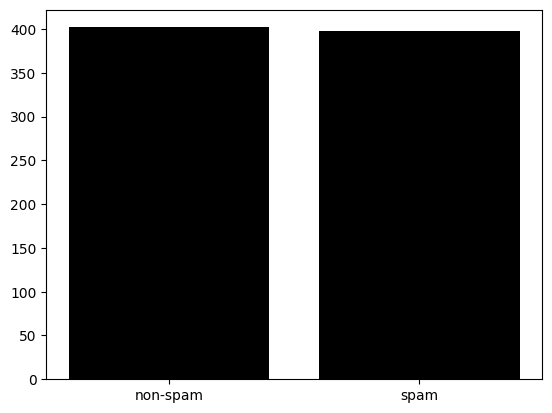

In [10]:
#Target column -barplot
xlab=df['label'].unique()
ylab=df['label'].value_counts()
plt.bar(xlab,ylab,color='black')
plt.show()

In [11]:
df['label']=df['label'].map({'non-spam':0,'spam':1})
df

,text,label
0,Thanks for your message. I will review the pre...,0
1,"Dear customer, your bank account has been sele...",1
2,"Dear customer, your email account has been sel...",1
3,Thanks for your message. I will review the pre...,0
4,Your appointment is confirmed for Friday at 2:...,0
...,...,...
795,"Your loan is pre-approved. Get up to â¹10,000...",1
796,"URGENT: Your account is eligible for a â¹10,0...",1
797,Don't forget to bring your phone for the the p...,0
798,Please find the presentation attached for tomo...,0


In [12]:
#defining text column to a variable
msg=df['text']
msg

,text
0,Thanks for your message. I will review the pre...
1,"Dear customer, your bank account has been sele..."
2,"Dear customer, your email account has been sel..."
3,Thanks for your message. I will review the pre...
4,Your appointment is confirmed for Friday at 2:...
...,...
795,"Your loan is pre-approved. Get up to â¹10,000..."
796,"URGENT: Your account is eligible for a â¹10,0..."
797,Don't forget to bring your phone for the the p...
798,Please find the presentation attached for tomo...


In [13]:
#TOKENIZATION
nltk.download('punkt_tab')
from nltk.tokenize import word_tokenize
msg=msg.apply(lambda x:word_tokenize(x)).apply(lambda x:" ".join(x))
msg

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


,text
0,Thanks for your message . I will review the pr...
1,"Dear customer , your bank account has been sel..."
2,"Dear customer , your email account has been se..."
3,Thanks for your message . I will review the pr...
4,Your appointment is confirmed for Friday at 2:...
...,...
795,"Your loan is pre-approved . Get up to â¹10,00..."
796,"URGENT : Your account is eligible for a â¹10,..."
797,Do n't forget to bring your phone for the the ...
798,Please find the presentation attached for tomo...


In [14]:
#removing special characters
msg=msg.replace('[^a-zA-Z0-9]'," ",regex=True)
msg

,text
0,Thanks for your message I will review the pr...
1,Dear customer your bank account has been sel...
2,Dear customer your email account has been se...
3,Thanks for your message I will review the pr...
4,Your appointment is confirmed for Friday at 2 ...
...,...
795,Your loan is pre approved Get up to 10 00...
796,URGENT Your account is eligible for a 10 ...
797,Do n t forget to bring your phone for the the ...
798,Please find the presentation attached for tomo...


In [15]:
#removing words with less than 3 letters
msg=msg.apply(lambda x:' '.join([i for i in word_tokenize(x) if len(i)>=3]))
msg

,text
0,Thanks for your message will review the presen...
1,Dear customer your bank account has been selec...
2,Dear customer your email account has been sele...
3,Thanks for your message will review the presen...
4,Your appointment confirmed for Friday Please a...
...,...
795,Your loan pre approved Get 000 with quick appr...
796,URGENT Your account eligible for 000 cash bonu...
797,forget bring your phone for the the project se...
798,Please find the presentation attached for tomo...


In [16]:
#STEMMING AND STOPWORD REMOVAL
nltk.download('stopwords')
from nltk.stem import SnowballStemmer
from nltk.corpus import stopwords
st=stopwords.words('english')
ss=SnowballStemmer('english')
msg=msg.apply(lambda x:" ".join([ss.stem(i.lower()) for i in word_tokenize(x) if i.lower() not in st]))
msg

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


,text
0,thank messag review present get back refer num...
1,dear custom bank account select special reward...
2,dear custom email account select special rewar...
3,thank messag review present get back refer num...
4,appoint confirm friday pleas arriv ten minut e...
...,...
795,loan pre approv get 000 quick approv appli today
796,urgent account elig 000 cash bonus click www c...
797,forget bring phone project session tomorrow
798,pleas find present attach tomorrow meet refer ...


In [17]:
#VECTORIZATION
from sklearn.feature_extraction.text import TfidfVectorizer
vec=TfidfVectorizer()
data=vec.fit_transform(msg)
data

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 7832 stored elements and shape (800, 693)>

In [18]:
#input and output selection
x=data
y=df['label']
print(x.shape)

(800, 693)


In [19]:
#TRAIN TEST SPLITTING
from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.30,random_state=41)
print(xtrain.shape)
print(ytrain.shape)
print(xtest.shape)
print(ytest.shape)

(560, 693)
(560,)
(240, 693)
(240,)


In [20]:
from sklearn.model_selection import GridSearchCV
#HYPERPARAMETER TUNING FOR KNN
from sklearn.neighbors import KNeighborsClassifier
knn_model=KNeighborsClassifier()
knn_param={'n_neighbors':[5,7,9,11],'weights':['distance','random'],'metric':['euclidean','manhattan']}
knn_grid=GridSearchCV(knn_model,knn_param,cv=3,scoring='accuracy')
knn_grid.fit(xtrain,ytrain)
knn_grid.best_params_


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
24 fits failed out of a total of 48.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
24 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1382, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 436, in _validate_params
    validate_par

{'metric': 'euclidean', 'n_neighbors': 5, 'weights': 'distance'}

In [21]:
#KNN MODEL BUILDING
knn=KNeighborsClassifier(metric= 'euclidean', n_neighbors=5, weights='distance')
knn.fit(xtrain,ytrain)
knn_ypred=knn.predict(xtest)
knn_ypred

array([0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0,
       1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0,
       0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0,
       0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1,
       0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0,
       0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1,
       1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1,
       1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0,
       0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0])

In [22]:
#HYPERPARAMETER TUNING FOR NB
from sklearn.naive_bayes import BernoulliNB
nb_model=BernoulliNB()
nb_param={'alpha':[0.1,0.5,1.0,5.0],'binarize':[0.0,0.5,1.0],'fit_prior':[True,False]}
nb_grid=GridSearchCV(nb_model,nb_param,cv=3,scoring='accuracy')
nb_grid.fit(xtrain,ytrain)
nb_grid.best_params_

{'alpha': 0.1, 'binarize': 0.0, 'fit_prior': True}

In [23]:
#NB MODEL BUILDING
nb=BernoulliNB(alpha= 0.1, binarize= 0.0, fit_prior=True)
nb.fit(xtrain,ytrain)
nb_ypred=nb.predict(xtest)
nb_ypred

array([0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0,
       1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0,
       0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0,
       0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1,
       0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0,
       0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1,
       1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1,
       1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0,
       0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0])

In [24]:
#HYPERPARAMETER TUNING FOR DT
from sklearn.tree import DecisionTreeClassifier
dt_model=DecisionTreeClassifier(random_state=41)
dt_param={'criterion':['gini','entropy','log_loss'],'max_depth':[5,7,10,None],'min_samples_split':[2,5,10],
          'min_samples_leaf':[1,2,4]}
dt_grid=GridSearchCV(dt_model,dt_param,cv=3,scoring='accuracy')
dt_grid.fit(xtrain,ytrain)
dt_grid.best_params_

{'criterion': 'gini',
 'max_depth': 7,
 'min_samples_leaf': 1,
 'min_samples_split': 2}

In [25]:
#DT MODEL BUILDING
dt=DecisionTreeClassifier(criterion= 'gini',max_depth= 7,min_samples_leaf= 1,min_samples_split=2,random_state=41)
dt.fit(xtrain,ytrain)
dt_ypred=dt.predict(xtest)
dt_ypred

array([0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0,
       1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0,
       0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0,
       0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1,
       0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0,
       0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1,
       1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1,
       1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0,
       0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0])

In [26]:
#HYPERPARAMETER TUNING FOR RFC
from sklearn.ensemble import RandomForestClassifier
rfc_model=RandomForestClassifier(random_state=41)
rfc_param={'n_estimators':[60,90,120],'max_depth':[5,10,15,None],'min_samples_split':[2,5,10],
          'min_samples_leaf':[1,2,4]}
rfc_grid=GridSearchCV(rfc_model,rfc_param,cv=3,scoring='accuracy')
rfc_grid.fit(xtrain,ytrain)
rfc_grid.best_params_

{'max_depth': 10,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'n_estimators': 60}

In [27]:
#RFC MODEL BUILDING
rfc=RandomForestClassifier(n_estimators=60,max_depth= 10,min_samples_leaf= 1,min_samples_split=2,random_state=41)
rfc.fit(xtrain,ytrain)
rfc_ypred=rfc.predict(xtest)
rfc_ypred

array([0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0,
       1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0,
       0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0,
       0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1,
       0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0,
       0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1,
       1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1,
       1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0,
       0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0])

In [28]:
#HYPERPARAMETER TUNING FOR XGB
from xgboost import XGBClassifier
xgb_model=XGBClassifier(random_state=41)
xgb_param={'n_estimators':[60,90,120],'max_depth':[5,10,15,None],'learning_rate':[0.01,0.1],'subsample':[0.8,1.0]}
xgb_grid=GridSearchCV(xgb_model,xgb_param,cv=3,scoring='accuracy')
xgb_grid.fit(xtrain,ytrain)
xgb_grid.best_params_

{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 60, 'subsample': 1.0}

In [29]:
#XGB MODEL BUILDING
xgb=XGBClassifier(n_estimators=60,max_depth= 5,learning_rate=0.1,subsample=1.0,random_state=41)
xgb.fit(xtrain,ytrain)
xgb_ypred=xgb.predict(xtest)
xgb_ypred

array([0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0,
       1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0,
       0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0,
       0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1,
       0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0,
       0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1,
       1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1,
       1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0,
       0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0])

In [30]:
#HYPERPARAMETER TUNING FOR LR
from sklearn.linear_model import LogisticRegression
lr_model=LogisticRegression()
lr_param={'C':[0.01,0.1,1,10,100],'penalty':['l1','l2'],'solver':['liblinear']}
lr_grid=GridSearchCV(lr_model,lr_param,cv=3,scoring='accuracy')
lr_grid.fit(xtrain,ytrain)
lr_grid.best_params_

{'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}

In [31]:
#LR MODEL BUILDING
lr=LogisticRegression(C=0.1, penalty='l2',solver='liblinear')
lr.fit(xtrain,ytrain)
lr_ypred=lr.predict(xtest)
lr_ypred

array([0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0,
       1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0,
       0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0,
       0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1,
       0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0,
       0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1,
       1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1,
       1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0,
       0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0])

In [32]:
#TRAINING AND TESTING SCORE
print("KNN Training_score:",knn.score(xtrain,ytrain),"Testing_score:",knn.score(xtest,ytest))
print("NB Training_score:",nb.score(xtrain,ytrain),"Testing_score:",nb.score(xtest,ytest))
print("DT Training_score:",dt.score(xtrain,ytrain),"Testing_score:",dt.score(xtest,ytest))
print("RFC Training_score:",rfc.score(xtrain,ytrain),"Testing_score:",rfc.score(xtest,ytest))
print("XGB Training_score:",xgb.score(xtrain,ytrain),"Testing_score:",xgb.score(xtest,ytest))
print("LR Training_score:",lr.score(xtrain,ytrain),"Testing_score:",lr.score(xtest,ytest))

KNN Training_score: 1.0 Testing_score: 1.0
NB Training_score: 1.0 Testing_score: 1.0
DT Training_score: 1.0 Testing_score: 1.0
RFC Training_score: 1.0 Testing_score: 1.0
XGB Training_score: 0.9982142857142857 Testing_score: 1.0
LR Training_score: 1.0 Testing_score: 1.0


In [33]:
#PERFORMANCE EVALUATION
from sklearn.metrics import accuracy_score
print("KNN accuracy_score:",accuracy_score(ytest,knn_ypred))
print("NB accuracy_score:",accuracy_score(ytest,nb_ypred))
print("DT accuracy_score:",accuracy_score(ytest,dt_ypred))
print("RFC accuracy_score:",accuracy_score(ytest,rfc_ypred))
print("XGB accuracy_score:",accuracy_score(ytest,xgb_ypred))
print("LR accuracy_score:",accuracy_score(ytest,lr_ypred))

KNN accuracy_score: 1.0
NB accuracy_score: 1.0
DT accuracy_score: 1.0
RFC accuracy_score: 1.0
XGB accuracy_score: 1.0
LR accuracy_score: 1.0


In [36]:
#NEW PREDICTIONS
new_data = pd.Series(["Dear customer,you bank account have been selected for a credit of 10000 rs"])
#tokenization
new_data = new_data.apply(lambda x: word_tokenize(x)).apply(lambda x: " ".join(x))
#removing special characters
new_data = new_data.replace('[^a-zA-Z0-9]', " ", regex=True)
#removing words with less than 3 letters
new_data = new_data.apply(lambda x: ' '.join([i for i in word_tokenize(x) if len(i) >= 3]))
#stemming and stopword removal
new_data = new_data.apply(lambda x: " ".join([ss.stem(i.lower()) for i in word_tokenize(x) if i.lower() not in st]))
#vectorization (transform only, not fit_transform)
vec1 = vec.transform(new_data)
#prediction
result = lr.predict(vec1)
print(result)   # 1 = spam, 0 = non-spam

[1]
